# Electronics Sales & Customer Analytics Dashboard

Business questions: which products and customers contribute completed-order revenue, how does spending vary over time, and how does a forecast compare with simple baselines?

The application uses completed orders for merchandise revenue and keeps cancelled orders separate. SHAP explains squared distance to a fixed cluster center; LIME explains a decision-tree surrogate of the segmentation. Neither explanation is a causal business driver.

## Setup
Run `python -m pip install -r requirements.txt` in the project folder. In Google Colab, run the setup cell below, then run `%pip install -r requirements.txt` before the analysis cell. No personal Google Drive or credentials are required.

In [1]:
from pathlib import Path
import os, subprocess
if not Path("analyze.py").exists():
    project = Path.cwd() / "SalesAnalyticsDashboard"
    if not (project / "analyze.py").exists():
        subprocess.run(["git", "clone", "https://github.com/YirenShen-07/SalesAnalyticsDashboard.git", str(project)], check=True)
    os.chdir(project)
print("Project:", Path.cwd().name)

Project: SalesAnalyticsDashboard


## Reproduce the analysis
The implementation lives in `analyze.py` so the CLI and notebook use the same definitions.

In [2]:
from analyze import run
results = run()
results.round(4)

                            MAE      RMSE
Model                                    
Trailing 7-day mean    25175.61  31198.74
Weekly seasonal naive  29892.21  38662.40
Prophet                24376.67  30768.01
{
  "Recorded order value": 63602668.370000005,
  "Completed merchandise revenue": 42629615.56999999,
  "Cancelled order value": 20973052.8,
  "Completed orders": 13432,
  "Cancelled orders": 6568
}
Out[0]: 
                              MAE        RMSE
Model                                        
Trailing 7-day mean    25175.6113  31198.7355
Weekly seasonal naive  29892.2107  38662.4040
Prophet                24376.6728  30768.0119


02:01:19 - cmdstanpy - INFO - Chain [1] start processing
02:01:19 - cmdstanpy - INFO - Chain [1] done processing
02:01:19 - cmdstanpy - INFO - Chain [1] start processing
02:01:19 - cmdstanpy - INFO - Chain [1] done processing


## Results and interpretation
These plots are regenerated by the preceding cell. Metrics and split metadata are also saved to `reports/`. Results are specific to this benchmark and fixed split; business improvements have not been measured.

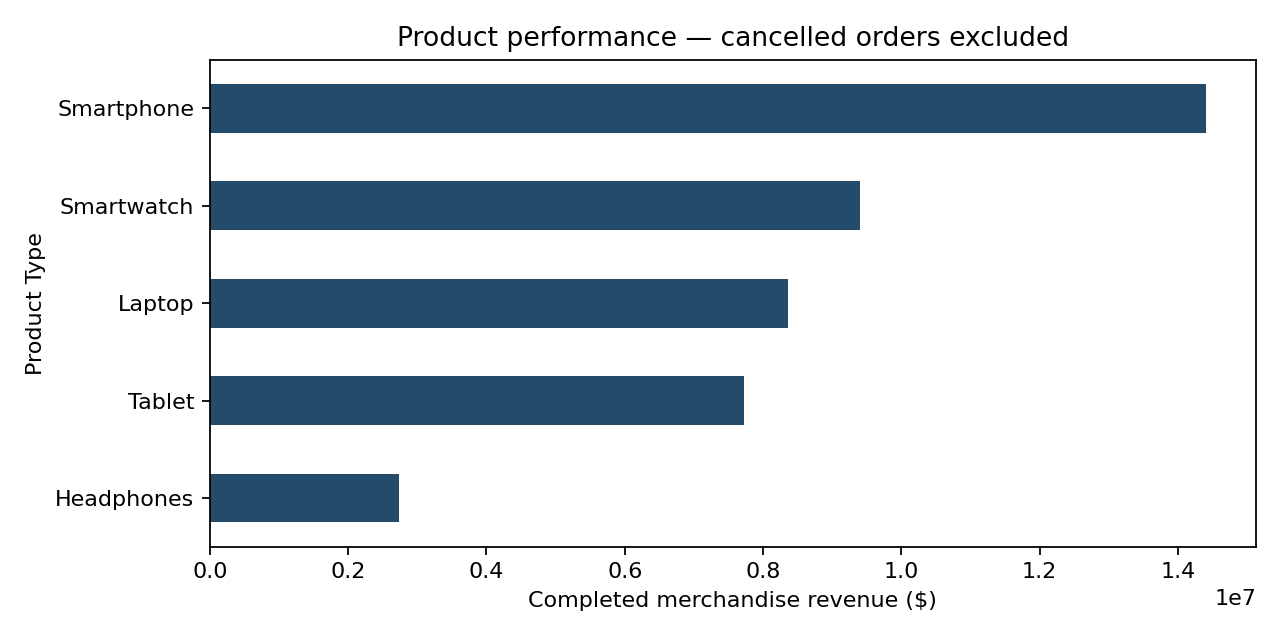

In [3]:
from IPython.display import Image, display
display(Image(filename="reports/product_revenue.png"))

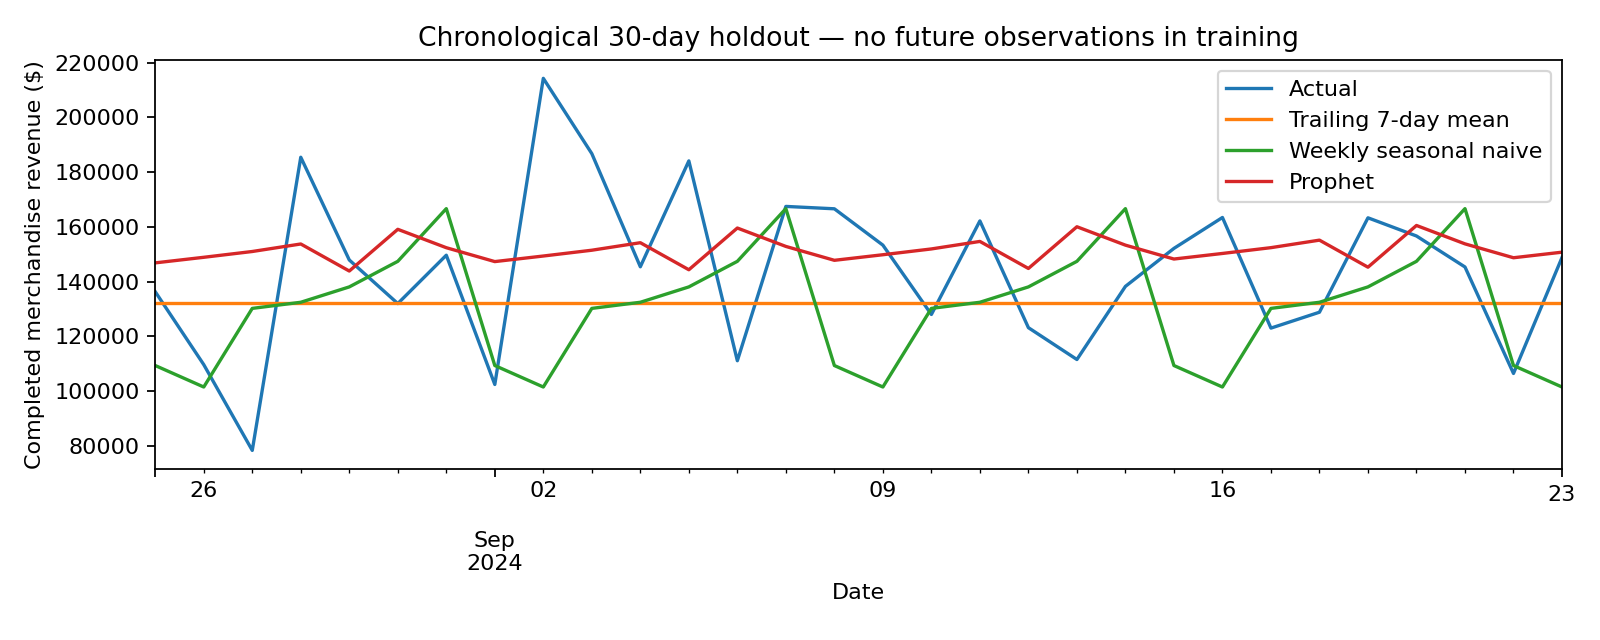

In [4]:
from IPython.display import Image, display
display(Image(filename="reports/backtest.png"))

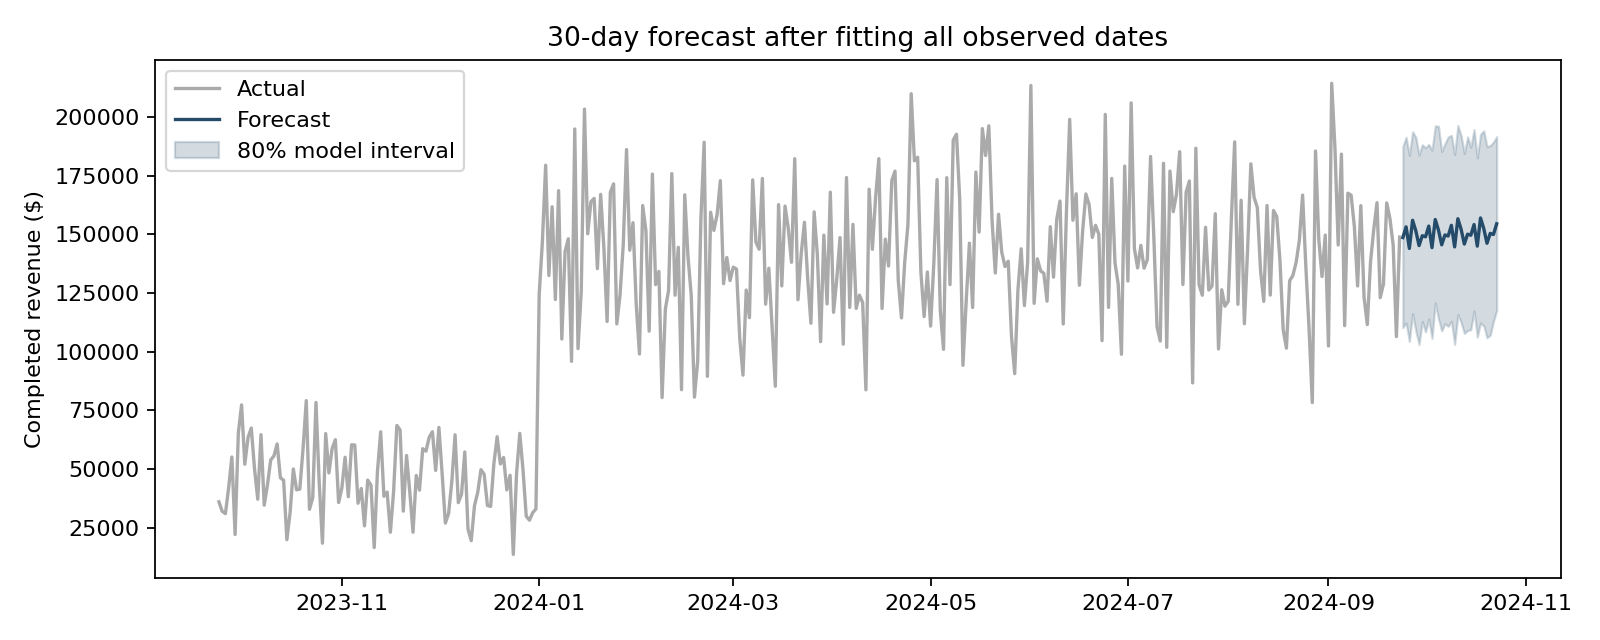

In [5]:
from IPython.display import Image, display
display(Image(filename="reports/forecast.png"))

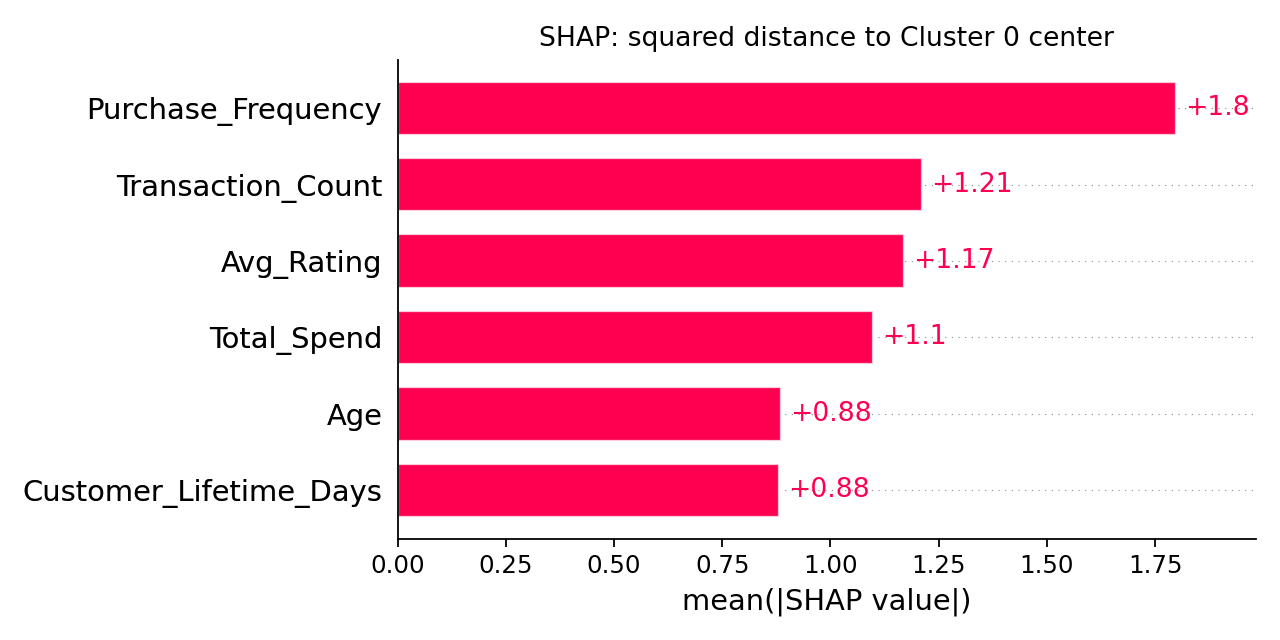

In [6]:
from IPython.display import Image, display
display(Image(filename="reports/shap_distance.png"))

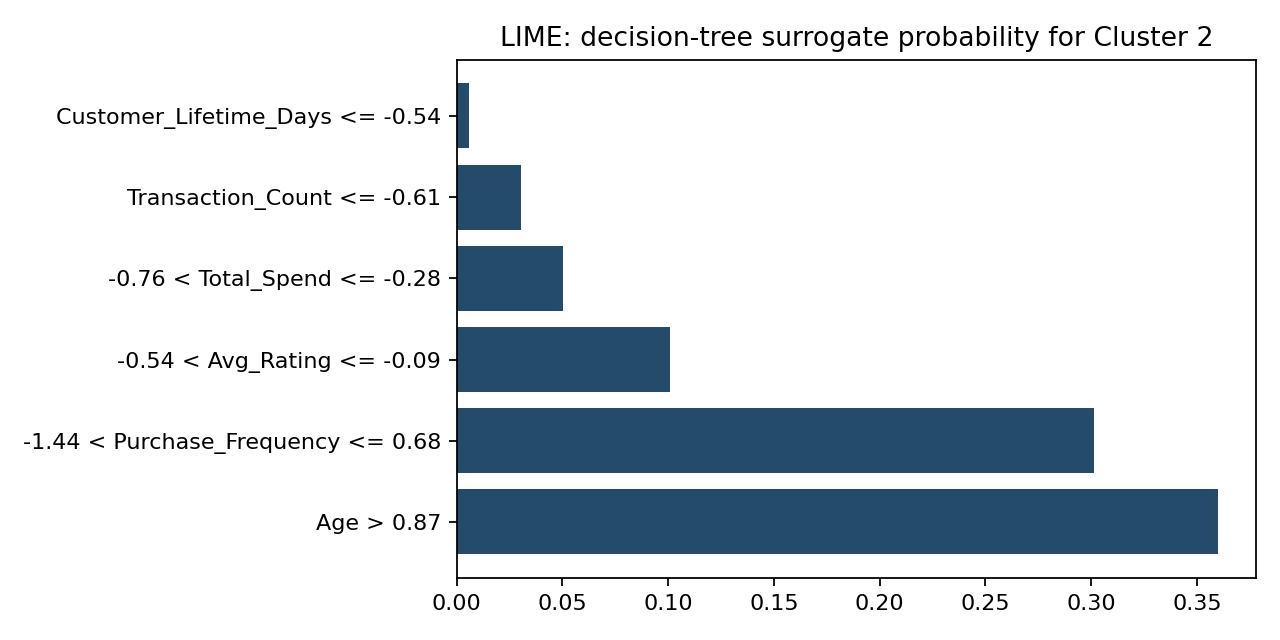

In [7]:
from IPython.display import Image, display
display(Image(filename="reports/lime_surrogate.png"))

## Sources and attribution
See [DATA.md](DATA.md) for sources, definitions, and fingerprints. The original project was developed by Yiren Shen for Duke AIPI 590. The 2026 portfolio maintenance pass adds reproducibility, evaluation and code corrections with AI assistance. Earlier coursework versions remain in Git history.